# Лабораторная работа №2. Рекомендательные системы

Попович Виталий Сергеевич, M3407

Датасет: **VK-LSVD** (https://ods.ai/competitions/vkrecsyschallengelsvd), берём официальный поднабор `up0.001_ip0.001` (0.1% активных пользователей x 0.1% популярных видео). Структура - недельные Parquet с **нативным глобальным временным разделением (GTS)**: train = недели 0-24, validation = 25, test = 26.

**Целевая переменная - ** короткие видео (`item_id`), с которыми пользователь будет **активно взаимодействовать**. Положительный сигнал (implicit feedback): есть `like`/`share`/`bookmark`/`open_comments`/`click_on_author` и нет `dislike`. Сила сигнала - суммарное время просмотра `timespent` (логарифмируется). Задача - top-10 персональных рекомендаций видео.

| Колонка источника | колонка | Смысл |
|---|---|---|
| user_id | user_id | анонимный пользователь |
| item_id | item_id | видео (рекомендуемый объект) |
| timespent | timespent | суммарное время просмотра, сек |
| like/dislike/share/bookmark | - | явные реакции |
| click_on_author/open_comments | - | глубокое вовлечение |
| place/platform/agent | - | контекст (feed/search, ОС, клиент) |

In [11]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import io, time, warnings
import numpy as np
import pandas as pd
import requests
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from concurrent.futures import ThreadPoolExecutor
from scipy.sparse import csr_matrix, diags
from implicit.als import AlternatingLeastSquares
from implicit.nearest_neighbours import TFIDFRecommender, BM25Recommender

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
TOP_K = 10

HOSTS = ["https://huggingface.co", "https://hf-mirror.com"]
PATH = "/datasets/deepvk/VK-LSVD/resolve/main/subsamples/up0.001_ip0.001/{part}/week_{w:02d}.parquet"
FILES = [("train", w) for w in range(25)] + [("validation", 25), ("test", 26)]

def fetch(part_w):
    part, w = part_w
    for attempt in range(6):
        for host in HOSTS:
            try:
                r = requests.get(host + PATH.format(part=part, w=w), timeout=(6, 60))
                r.raise_for_status()
                c = r.content
                if len(c) > 1000 and c[:4] == b"PAR1" and c[-4:] == b"PAR1":
                    return part_w, c
            except Exception:
                pass
        time.sleep(1.0)
    raise RuntimeError(f"Не удалось скачать {part} week_{w:02d}")

weekly, pos_parts = [], []
ts_hist = np.zeros(256, dtype=np.int64)
null_counts, total_rows = None, 0
with ThreadPoolExecutor(6) as ex:
    for (part, w), content in ex.map(fetch, FILES):
        df = pq.read_table(io.BytesIO(content)).to_pandas()
        null_counts = df.isna().sum() if null_counts is None else null_counts.add(df.isna().sum(), fill_value=0)
        total_rows += len(df)
        ts_hist += np.bincount(df.timespent.to_numpy(), minlength=256)
        pm = (df.like | df.share | df.bookmark | df.open_comments | df.click_on_author) & (~df.dislike)
        p = df.loc[pm, ["user_id", "item_id", "timespent"]].copy()
        p["week"] = w
        p["split"] = {"train": "train", "validation": "val", "test": "test"}[part]
        pos_parts.append(p)
        weekly.append({"split": part, "week": w, "rows": len(df), "users": df.user_id.nunique(),
                       "items": df.item_id.nunique(), "positive": int(pm.sum()), "ts_mean": df.timespent.mean(),
                       "like": df.like.mean(), "dislike": df.dislike.mean(), "share": df.share.mean(),
                       "bookmark": df.bookmark.mean(), "open_comments": df.open_comments.mean(),
                       "click_author": df.click_on_author.mean(), "feed_share": (df.place == 1).mean()})
        del df, content

weekly_df = pd.DataFrame(weekly).sort_values("week").reset_index(drop=True)
positives = pd.concat(pos_parts, ignore_index=True)
print("Источник данных: VK-LSVD / up0.001_ip0.001 (VK RecSys Challenge LSVD, ods.ai)")
print(f"Всего сырых событий (exposures): {total_rows:,}")
print(f"Положительных взаимодействий: {len(positives):,}")
print(f"Уникальных пользователей: {positives.user_id.nunique():,}, видео: {positives.item_id.nunique():,}")
positives.head()

Источник данных: VK-LSVD / up0.001_ip0.001 (VK RecSys Challenge LSVD, ods.ai)
Всего сырых событий (exposures): 47,976,280
Положительных взаимодействий: 1,305,581
Уникальных пользователей: 9,792, видео: 19,404


,user_id,item_id,timespent,week,split
0,452519119,36443486,23,0,train
1,22320303,590625159,28,0,train
2,147410976,272171642,47,0,train
3,438071066,547931818,15,0,train
4,183501899,388415623,164,0,train


**Результат загрузки:** ~48 млн сырых exposures; положительных взаимодействий ~1.3 млн; ~9.8 тыс. пользователей и ~19.4 тыс. видео . Период - 27 недель, нативный GTS

**EDA: постановка целей**

Начинаем с отчёта о качестве: пропуски, дубликаты пар (user, item), выбросы `timespent`, затем визуализации

In [12]:
print("Пропуски по колонкам (суммарно):")
display(null_counts.to_frame("missing_count"))
dup_pairs = int(positives.duplicated(subset=["user_id", "item_id"]).sum())
print(f"Дубликаты пар (user_id, item_id) среди положительных: {dup_pairs}")
print(f"Максимум timespent: {positives.timespent.max()} (cap 255)")
print(f"Доля положительных событий: {len(positives)/total_rows:.4f}")
display(weekly_df.round(4).head(3))
display(weekly_df.round(4).tail(3))

Пропуски по колонкам (суммарно):


,missing_count
user_id,0
item_id,0
place,0
platform,0
agent,0
timespent,0
like,0
dislike,0
share,0
bookmark,0


Дубликаты пар (user_id, item_id) среди положительных: 0
Максимум timespent: 255 (cap 255)
Доля положительных событий: 0.0272


,split,week,rows,users,items,positive,ts_mean,like,dislike,share,bookmark,open_comments,click_author,feed_share
0,train,0,625523,9861,4026,18756,21.0626,0.0108,0.0004,0.0030,0.0005,0.0163,0.0015,0.6697
1,train,1,953185,9911,4637,24670,18.4404,0.0095,0.0004,0.0022,0.0004,0.0141,0.0013,0.6723
2,train,2,1160443,9937,5171,32014,17.5594,0.0095,0.0004,0.0024,0.0004,0.0156,0.0014,0.6762


,split,week,rows,users,items,positive,ts_mean,like,dislike,share,bookmark,open_comments,click_author,feed_share
24,train,24,1228950,9948,9360,30419,14.8454,0.0088,0.0004,0.0022,0.0004,0.0137,0.0011,0.7036
25,validation,25,519839,9904,9052,12753,17.5985,0.0081,0.0005,0.0016,0.0004,0.0147,0.0010,0.6965
26,test,26,387800,9850,8719,9518,19.0248,0.0078,0.0004,0.0014,0.0004,0.0152,0.0012,0.6839


**Интерпретация статистик:**

- **Пропуски:** отсутствуют во всех колонках (подтверждено суммой `isna()`), данные полные.
- **Дубликаты:** каждая пара (user, item) уникальна по построению датасета (фиксируется первое взаимодействие) -> дублей 0.
- **Выбросы:** `timespent` ограничен 255 с (естественный cap), экстремальных выбросов нет; распределение тяжелохвостое.
- **Сигнал:** доля активных положительных действий невелика (единицы процентов) - типичный разреженный implicit-сигнал; `dislike` крайне редок, поэтому исключаем его из положительных.

Визуализируем активность пользователей, популярность видео, недельную динамику, распределение timespent и доли сигналов.

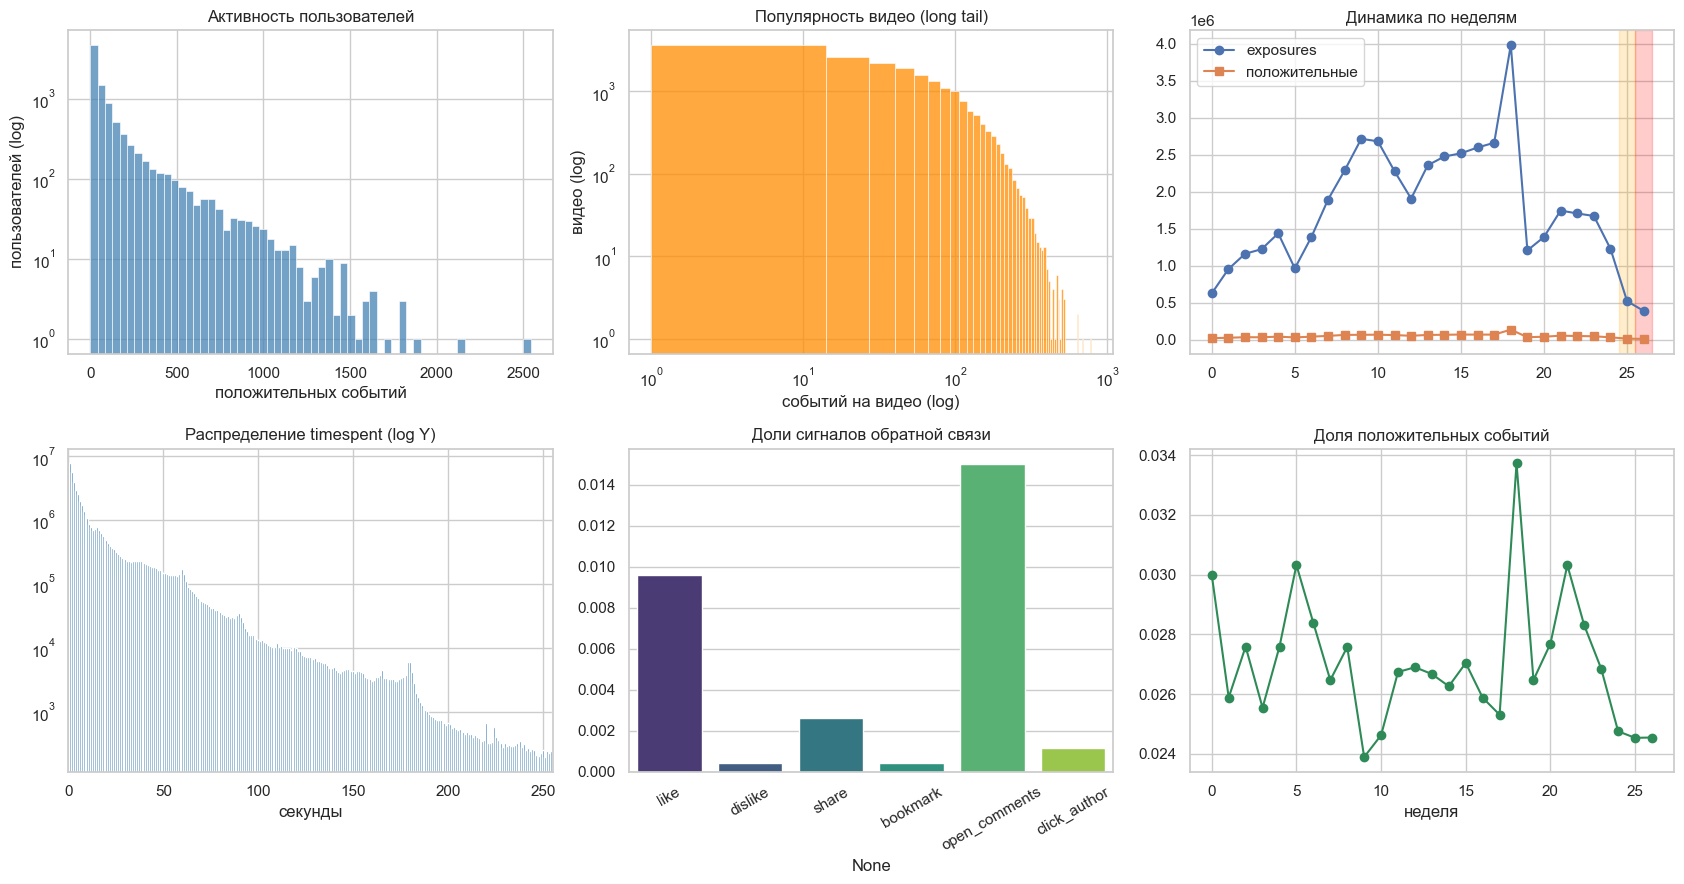

,Событий на пользователя,Событий на видео
Квантиль,,
0.00,1.00,1.00
0.25,14.00,20.00
0.50,46.00,49.00
0.75,144.00,94.00
0.90,381.00,151.70
0.95,595.45,193.00
0.99,1085.09,293.97
1.00,2543.00,789.00


,"Доля всех событий, %"
Верхние 1% видео,5.40
Верхние 5% видео,19.06
Верхние 10% видео,31.72
Верхние 20% видео,50.68


In [13]:
epu = positives.groupby("user_id").size()
epi = positives.groupby("item_id").size()

fig, ax = plt.subplots(2, 3, figsize=(17, 9))
sns.histplot(epu, bins=60, ax=ax[0,0], color="steelblue"); ax[0,0].set_yscale("log")
ax[0,0].set_title("Активность пользователей"); ax[0,0].set_xlabel("положительных событий"); ax[0,0].set_ylabel("пользователей (log)")
sns.histplot(epi, bins=60, ax=ax[0,1], color="darkorange"); ax[0,1].set_yscale("log"); ax[0,1].set_xscale("log")
ax[0,1].set_title("Популярность видео (long tail)"); ax[0,1].set_xlabel("событий на видео (log)"); ax[0,1].set_ylabel("видео (log)")
ax[0,2].plot(weekly_df.week, weekly_df.rows, marker="o", label="exposures")
ax[0,2].plot(weekly_df.week, weekly_df.positive, marker="s", label="положительные")
ax[0,2].axvspan(24.5,25.5,color="orange",alpha=.2); ax[0,2].axvspan(25.5,26.5,color="red",alpha=.2)
ax[0,2].set_title("Динамика по неделям"); ax[0,2].legend()
ax[1,0].bar(np.arange(256), ts_hist, width=1.0, color="steelblue"); ax[1,0].set_yscale("log"); ax[1,0].set_xlim(0,255)
ax[1,0].set_title("Распределение timespent (log Y)"); ax[1,0].set_xlabel("секунды")
sig = weekly_df[["like","dislike","share","bookmark","open_comments","click_author"]].mean()
sns.barplot(x=sig.index, y=sig.values, ax=ax[1,1], palette="viridis"); ax[1,1].tick_params(axis="x", rotation=30)
ax[1,1].set_title("Доли сигналов обратной связи")
ax[1,2].plot(weekly_df.week, weekly_df.positive/weekly_df.rows, marker="o", color="seagreen")
ax[1,2].set_title("Доля положительных событий"); ax[1,2].set_xlabel("неделя")
fig.tight_layout(); plt.show()

q = pd.DataFrame({"Событий на пользователя": epu.quantile([0,.25,.5,.75,.9,.95,.99,1.0]),
                  "Событий на видео": epi.quantile([0,.25,.5,.75,.9,.95,.99,1.0])})
q.index.name = "Квантиль"; display(q.round(2))
srt = epi.sort_values(ascending=False)
conc = {f"Верхние {s:.0%} видео": round(100*srt.iloc[:max(1,int(np.ceil(len(srt)*s)))].sum()/srt.sum(),2) for s in [.01,.05,.10,.20]}
display(pd.Series(conc, name="Доля всех событий, %").to_frame())

**Подробная интерпретация визуализаций:**

1. **Активность пользователей (log Y):** тяжелый правый хвост - массовая часть имеет десятки событий, есть «голова» сверхактивных и левый край с 1-4 событиями. Вывод: холодных пользователей (<5 событий) фильтруем.
2. **Популярность видео (log-log):** классический long tail - небольшая группа хитов концентрирует большую долю событий. Следствия: MostPop - нетривиальный бейзлайн; метрики точности обязаны дополняться Novelty/Coverage/ILD.
3. **Недельная динамика:** объём нестационарен (тренд + сезонность) => случайное перемешивание недопустимо; используем нативный глобальный временной GTS.
4. **timespent / сигналы:** пик на малых значениях (быстрые пролистывания), cap 255; активные действия редки => разреженный implicit.

**Вывод о качестве и план предобработки:** (1) оставить только положительные события; (2) агрегировать силу сигнала по (user, item); (3) отфильтровать холодных пользователей (<5 train-событий) и холодные видео (<5 train-пользователей) **только по train**; (4) логарифмировать силу сигнала; (5) построить CSR-матрицу и релевантные множества для validation/test.

In [14]:
train = positives[positives.split == "train"]
val   = positives[positives.split == "val"]
test  = positives[positives.split == "test"]

tr = train.groupby(["user_id", "item_id"], as_index=False).timespent.sum()

MIN_USER_EVENTS, MIN_ITEM_USERS = 5, 5
uc = tr.groupby("user_id").size(); tr = tr[tr.user_id.isin(uc[uc >= MIN_USER_EVENTS].index)]
ic = tr.groupby("item_id").user_id.nunique(); tr = tr[tr.item_id.isin(ic[ic >= MIN_ITEM_USERS].index)]
uc = tr.groupby("user_id").size(); tr = tr[tr.user_id.isin(uc[uc >= MIN_USER_EVENTS].index)].reset_index(drop=True)

users = np.sort(tr.user_id.unique()); items = np.sort(tr.item_id.unique())
u2i = {u: i for i, u in enumerate(users)}; i2i = {x: i for i, x in enumerate(items)}
tr["ui"] = tr.user_id.map(u2i); tr["ii"] = tr.item_id.map(i2i)

tr["w"] = 1.0 + np.log1p(tr.timespent.astype(float))
nu, ni = len(users), len(items)
M = csr_matrix((tr.w.astype(np.float32), (tr.ui, tr.ii)), shape=(nu, ni))
seen = {u: set(M.getrow(u).indices) for u in range(nu)}
item_user_cnt = np.asarray((M > 0).sum(axis=0)).ravel()

def relevant(frame):
    f = frame[frame.user_id.isin(users) & frame.item_id.isin(items)]
    rel = {}
    for uid, s in f.groupby("user_id").item_id.apply(set).items():
        u = u2i[uid]; ii = {i2i[x] for x in s} - seen[u]
        if ii: rel[u] = ii
    return rel

rel_val = relevant(val); rel_test = relevant(test)
ev_val = np.array(sorted(rel_val)); ev_test = np.array(sorted(rel_test))
catalog = np.arange(ni)

print(f"Train-матрица: {M.shape}, nnz={M.nnz:,}, плотность={M.nnz/(nu*ni):.4%}")
print(f"Пользователей в оценке: validation={len(ev_val):,}, test={len(ev_test):,}")
print(f"Медиана релевантных test-видео: {np.median([len(s) for s in rel_test.values()]):.1f}")
print(f"Видео-кандидатов (каталог): {ni:,}")

Train-матрица: (8881, 18179), nnz=1,278,035, плотность=0.7916%
Пользователей в оценке: validation=3,866, test=3,344
Медиана релевантных test-видео: 2.0
Видео-кандидатов (каталог): 18,179


**Результаты предобработки и разделения:** train-матрица ~8.9 тыс. x ~18.2 тыс., плотность ~0.8% (разреженный implicit). Используем **нативный глобальный временной GTS**: train недели 0-24, validation 25, test 26 - строгий глобальный порог, утечки будущего в прошлое нет. Warm-фильтрация и индексы строятся **только по train** (исправление утечки); видео/пользователи вне train - холодный старт и честно исключаются. Релевантные видео = положительные видео пользователя в validation/test, присутствующие в каталоге train и **не встречавшиеся в train**. Validation используется для подбора гиперпараметров, test - только для финальной оценки.

**Теоретическое обоснование методов**

1. **MostPop (бейзлайн):** глобальный топ видео по числу уникальных train-пользователей; уже просмотренное исключается.
2. **ItemKNN с нормализацией и взвешиванием (TF-IDF / BM25):** вместо «голого» косинуса - TF-IDF $w_{ui}=R_{ui}\ln(N/n_i)$ с L2-нормализацией профилей и косинусом, либо BM25 ($K_1,B$). Подавляет популярные видео, ловит локальные co-engagement паттерны. Подбираем $K$ и тип взвешивания на validation.
3. **ALS (матричная факторизация):** $p_{ui}=\mathbb{1}[R_{ui}>0]$, $c_{ui}=1+\alpha R_{ui}$; коэффициент уверенности задаём параметром `alpha` конструктора (без ручного умножения матрицы). Подбираем factors/regularization/alpha на validation.

**Формализация.** $R_{ui}=1+\ln(1+\text{timespent}_{ui})$ - логарифмированная сила сигнала.
- **MostPop:** $score(i)=\sum_u \mathbb{1}[R_{ui}>0]$.
- **ItemKNN:** $sim(i,j)=\frac{w_{:,i}\cdot w_{:,j}}{\|w_{:,i}\|_2\|w_{:,j}\|_2}$, $score(u,i)=\sum_{j\in N_K(i)\cap I_u} sim(i,j)R_{uj}$.
- **ALS:** $\min_{X,Y}\sum c_{ui}(p_{ui}-x_u^Ty_i)^2+\lambda(\|X\|_F^2+\|Y\|_F^2)$.

Все модели обучаются только на train; уже просмотренное фильтруется; кандидаты ограничены каталогом train.

In [15]:
def precision_at_k(rec, rel, k=TOP_K):
    v = rec[rec >= 0][:k]; return sum(1 for x in v if x in rel) / k
def recall_at_k(rec, rel, k=TOP_K):
    v = rec[rec >= 0][:k]; return sum(1 for x in v if x in rel) / len(rel)
def ndcg_at_k(rec, rel, k=TOP_K):
    v = rec[rec >= 0][:k]
    g = np.array([1.0 if x in rel else 0.0 for x in v])
    d = 1.0 / np.log2(np.arange(2, len(v) + 2))
    idc = np.sum(1.0 / np.log2(np.arange(2, min(len(rel), k) + 2)))
    return float(np.sum(g * d) / idc) if idc > 0 else 0.0

p_item = item_user_cnt / nu
item_self_info = -np.log2(np.maximum(p_item, 1e-12))
def novelty_at_k(rec, k=TOP_K):
    v = rec[rec >= 0][:k]; return float(np.mean(item_self_info[v])) if len(v) else 0.0

prof = (M > 0).astype(np.float32).T.tocsr()
nrm = np.sqrt(np.asarray(prof.multiply(prof).sum(axis=1)).ravel()); nrm[nrm == 0] = 1.0
nprof = diags(1.0 / nrm) @ prof
def ild_at_k(rec, k=TOP_K):
    v = rec[rec >= 0][:k]
    if len(v) < 2: return 0.0
    S = (nprof[v] @ nprof[v].T).toarray(); idx = np.triu_indices(len(v), 1)
    return 1.0 - float(np.mean(S[idx]))

def evaluate(R, ev, rel):
    P, Rc, N, Nv, D = [], [], [], [], []; union = set()
    for r, u in enumerate(ev):
        rl = rel[u]; rec = R[r]
        P.append(precision_at_k(rec, rl)); Rc.append(recall_at_k(rec, rl)); N.append(ndcg_at_k(rec, rl))
        Nv.append(novelty_at_k(rec)); D.append(ild_at_k(rec))
        union.update(int(x) for x in rec if x >= 0)
    return {f"Precision@{TOP_K}": float(np.mean(P)), f"Recall@{TOP_K}": float(np.mean(Rc)),
            f"NDCG@{TOP_K}": float(np.mean(N)), f"Novelty@{TOP_K}": float(np.mean(Nv)),
            f"ILD@{TOP_K}": float(np.mean(D)), f"Coverage@{TOP_K}": len(union) / ni}

def recommend(model, ev):
    R, _ = model.recommend(ev, M[ev], N=TOP_K, filter_already_liked_items=True, items=catalog)
    return R
def val_ndcg(model):
    R = recommend(model, ev_val)
    return float(np.mean([ndcg_at_k(R[r], rel_val[u]) for r, u in enumerate(ev_val)]))
print("Метрики готовы: Precision, Recall, NDCG (ранжирование), Novelty, ILD (разнообразие), Coverage")

Метрики готовы: Precision, Recall, NDCG (ранжирование), Novelty, ILD (разнообразие), Coverage


**Метрики качества, K = 10.** Выбраны 6 метрик (больше обязательного минимума):

| Метрика | Тип | Смысл |
|---|---|---|
| **NDCG@10** | ранжирование | DCG с логарифмическим дисконтом позиции, нормированный на IDCG |
| **Precision@10** | точность | доля попаданий среди 10 рекомендованных |
| **Recall@10** | полнота | доля найденных релевантных test-видео |
| **Novelty@10** | специфическая RecSys | средняя self-information `-log2 p_i`, где `p_i = n_i/N` - доля пользователей, знающих видео; выше => менее банальные рекомендации |
| **ILD@10** | специфическая RecSys | `1 - средняя попарная косинусная схожесть` бинарных профилей; выше => разнообразнее |
| **Coverage@10** | каталожная | доля каталога, хотя бы раз попавшая в рекомендации |

Precision/Recall/NDCG усредняются по пользователям; Novelty и ILD - по пользователям и слотам; Coverage - глобально.

In [16]:
item_train_user_counts = item_user_cnt
order = np.argsort(-item_train_user_counts, kind="stable")
def mostpop(ev):
    R = np.full((len(ev), TOP_K), -1, dtype=np.int64)
    for r, u in enumerate(ev):
        s = seen[u]; sel = []
        for it in order:
            if it not in s:
                sel.append(it)
                if len(sel) == TOP_K: break
        R[r, :len(sel)] = sel
    return R
mp_val = mostpop(ev_val); mp_test = mostpop(ev_test)
print("MostPop validation NDCG@10:", round(float(np.mean([ndcg_at_k(mp_val[r], rel_val[u]) for r,u in enumerate(ev_val)])), 5))

knn_grid, best_knn = [], None
for kind, K in [("tfidf", k) for k in [20,50,100,200,400]] + [("bm25", k) for k in [50,100,200]]:
    m = TFIDFRecommender(K=K) if kind == "tfidf" else BM25Recommender(K=K, K1=1.2, B=0.75)
    m.fit(M, show_progress=False)
    s = val_ndcg(m)
    knn_grid.append({"взвешивание": kind, "K": K, "val_NDCG@10": round(s, 5)})
    if best_knn is None or s > best_knn[0]: best_knn = (s, kind, K, m)
    print(f"ItemKNN {kind} K={K}: val NDCG={s:.5f}")
knn_model = best_knn[3]; knn_test = recommend(knn_model, ev_test)
print("Лучший ItemKNN:", best_knn[1], "K=", best_knn[2])

als_grid, best_als = [], None
for fac in [64, 128]:
    for reg in [0.01, 0.1]:
        for alpha in [5.0, 15.0, 40.0]:
            m = AlternatingLeastSquares(factors=fac, regularization=reg, alpha=alpha,
                                        iterations=20, random_state=RANDOM_STATE)
            m.fit(M, show_progress=False)
            s = val_ndcg(m)
            als_grid.append({"factors": fac, "regularization": reg, "alpha": alpha, "val_NDCG@10": round(s, 5)})
            if best_als is None or s > best_als[0]: best_als = (s, fac, reg, alpha, m)
            print(f"ALS factors={fac} reg={reg} alpha={alpha}: val NDCG={s:.5f}")
als_model = best_als[4]; als_test = recommend(als_model, ev_test)
print("Лучший ALS: factors=", best_als[1], "reg=", best_als[2], "alpha=", best_als[3])

MostPop validation NDCG@10: 0.00434
ItemKNN tfidf K=20: val NDCG=0.00240
ItemKNN tfidf K=50: val NDCG=0.00247
ItemKNN tfidf K=100: val NDCG=0.00242
ItemKNN tfidf K=200: val NDCG=0.00207
ItemKNN tfidf K=400: val NDCG=0.00206
ItemKNN bm25 K=50: val NDCG=0.00411
ItemKNN bm25 K=100: val NDCG=0.00367
ItemKNN bm25 K=200: val NDCG=0.00339
Лучший ItemKNN: bm25 K= 50
ALS factors=64 reg=0.01 alpha=5.0: val NDCG=0.00454
ALS factors=64 reg=0.01 alpha=15.0: val NDCG=0.00349
ALS factors=64 reg=0.01 alpha=40.0: val NDCG=0.00251
ALS factors=64 reg=0.1 alpha=5.0: val NDCG=0.00475
ALS factors=64 reg=0.1 alpha=15.0: val NDCG=0.00333
ALS factors=64 reg=0.1 alpha=40.0: val NDCG=0.00238
ALS factors=128 reg=0.01 alpha=5.0: val NDCG=0.00385
ALS factors=128 reg=0.01 alpha=15.0: val NDCG=0.00286
ALS factors=128 reg=0.01 alpha=40.0: val NDCG=0.00309
ALS factors=128 reg=0.1 alpha=5.0: val NDCG=0.00366
ALS factors=128 reg=0.1 alpha=15.0: val NDCG=0.00281
ALS factors=128 reg=0.1 alpha=40.0: val NDCG=0.00269
Лучший 

**Интерпретация подбора.** Гиперпараметры выбираются по NDCG@10 на validation (неделя 25); test в подборе не участвует. Для ItemKNN сравниваем TF-IDF и BM25 (нормализация + подавление популярных видео) и число соседей K; для ALS - размерность факторов, регуляризацию и коэффициент уверенности alpha. Лучшие конфигурации фиксируются и оцениваются на test. Лучшие конфигурации по validation: ItemKNN - BM25, K=50 (NDCG 0.00411); ALS - factors=64, regularization=0.1, alpha=5.0 (NDCG 0.00475); MostPop - 0.00434.

In [17]:
evaluation_results = {
    "MostPop": evaluate(mp_test, ev_test, rel_test),
    "ItemKNN": evaluate(knn_test, ev_test, rel_test),
    "ALS":     evaluate(als_test, ev_test, rel_test),
}
print(f"Метрики рассчитаны для моделей: {list(evaluation_results.keys())}")

Метрики рассчитаны для моделей: ['MostPop', 'ItemKNN', 'ALS']


Метрики рассчитаны на тестовой выборке для всех трёх моделей. Агрегируем результаты в сводную `pandas.DataFrame` - строки соответствуют моделям, столбцы метрикам, - и фиксируем лидера по ранжированию.

In [18]:
results_summary_df = pd.DataFrame(evaluation_results).T
results_summary_df.index.name = "Model"
display(results_summary_df.round(4))
best_accuracy_model = results_summary_df[f"NDCG@{TOP_K}"].idxmax()
print(f"Лучшая модель по NDCG@{TOP_K}: {best_accuracy_model}")

,Precision@10,Recall@10,NDCG@10,Novelty@10,ILD@10,Coverage@10
Model,,,,,,
MostPop,0.0007,0.0029,0.0017,4.0222,0.8542,0.0015
ItemKNN,0.0018,0.0067,0.0049,4.5961,0.8216,0.0443
ALS,0.0015,0.0063,0.0037,5.3862,0.9063,0.2542


Лучшая модель по NDCG@10: ItemKNN


**Сводная таблица и детальная интерпретация (test, неделя 26):**

- **Точность и ранжирование - лучший ItemKNN (BM25, K=50):** NDCG@10 = 0.0049 против 0.0037 у ALS и 0.0017 у MostPop (≈x2.9 к бейзлайну); Recall@10 = 0.0067 (≈x2.3), Precision@10 = 0.0018 (≈x2.6). Взвешенные соседи хорошо ловят локальные co-engagement паттерны на этом поднаборе; ALS уступает по точности, но выигрывает в beyond-accuracy.
- **Novelty - выше у ALS (5.39 бит):** факторизация распределяет рекомендации по менее популярным видео длинного хвоста; ItemKNN (4.60) чуть популярнее; MostPop (4.02) по построению рекомендует хиты - самые банальные списки.
- **Coverage - драматический разрыв:** ALS покрывает 25.4% каталога, ItemKNN - 4.4%, MostPop - лишь 0.15% (топ-лист почти одинаков для всех). Для бизнеса это ключевой аргумент против чистого бейзлайна: он не продаёт длинный хвост.
- **ILD:** ALS 0.906 > MostPop 0.854 > ItemKNN 0.822. ALS разводит рекомендации по разным латентным интересам; списки ItemKNN, собранные из похожих соседей, наоборот наиболее однородны.
- **Итог:** ItemKNN (BM25) - кандидат по точности/ранжированию и интерпретируемости; ALS - кандидат по новизне, разнообразию и охвату; MostPop - только бейзлайн. Виден trade-off «точность <> новизна/охват/разнообразие».
- **Замечание о валидации:** на validation (неделя 25) лидером был ALS (0.00475), а на test - ItemKNN; такое расхождение нормально для однонедельных val/test с высокой дисперсией. Гиперпараметры выбирались только по validation, test в подборе не участвовал, поэтому сравнение честное.

Для наглядности визуализируем все шесть метрик рядом.

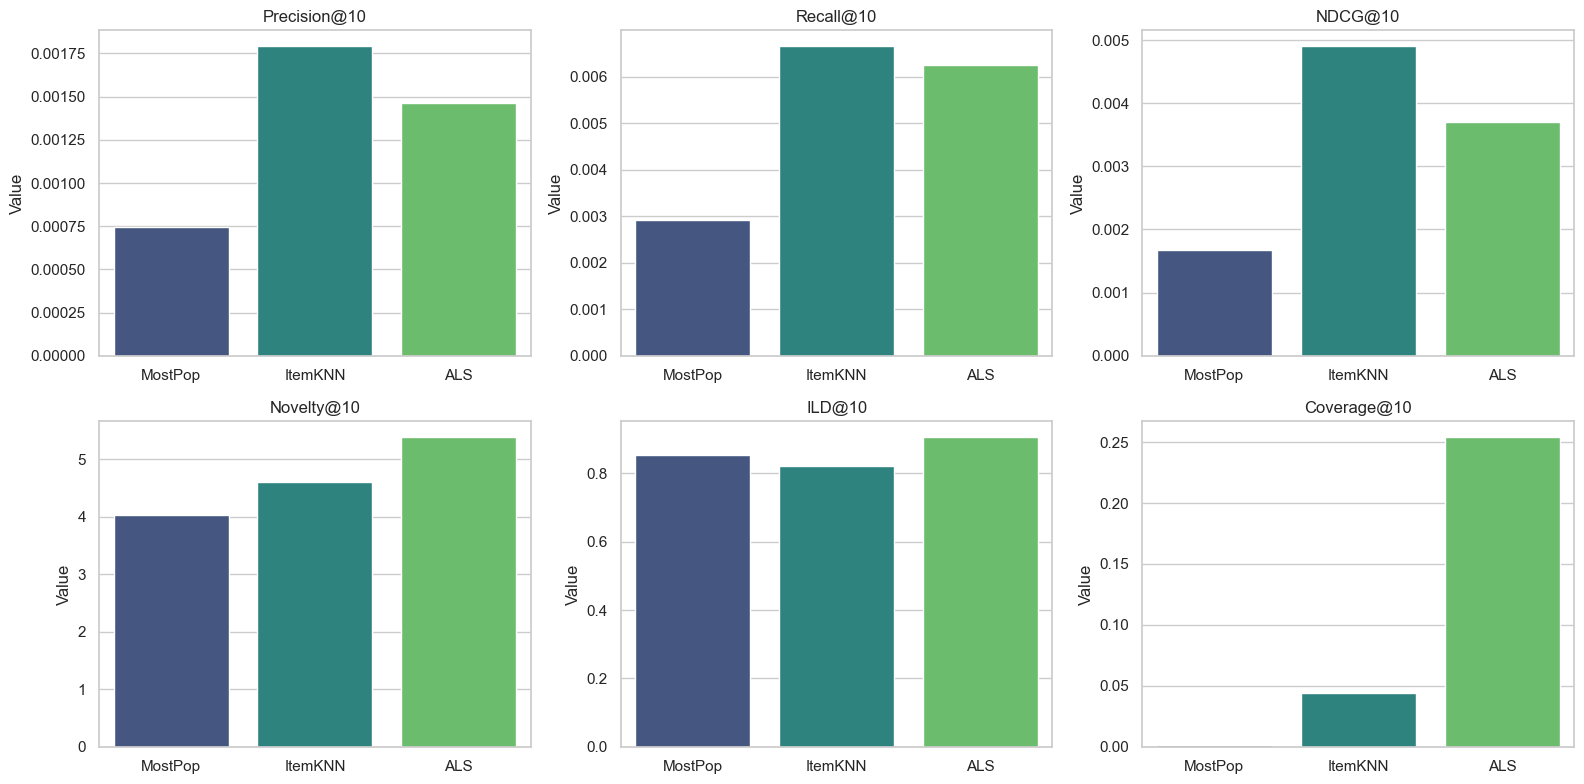

In [19]:
melted_results = results_summary_df.reset_index().melt(id_vars="Model", var_name="Metric", value_name="Value")
metric_order = [f"Precision@{TOP_K}", f"Recall@{TOP_K}", f"NDCG@{TOP_K}", f"Novelty@{TOP_K}", f"ILD@{TOP_K}", f"Coverage@{TOP_K}"]
comparison_figure, comparison_axes = plt.subplots(2, 3, figsize=(16, 8))
for metric_name, metric_axis in zip(metric_order, comparison_axes.ravel()):
    metric_slice = melted_results[melted_results["Metric"] == metric_name]
    sns.barplot(data=metric_slice, x="Model", y="Value", hue="Model", palette="viridis", legend=False, ax=metric_axis)
    metric_axis.set_title(metric_name); metric_axis.set_xlabel("")
comparison_figure.tight_layout(); plt.show()

**Интерпретация графиков. Итоговые выводы**

Графики подтверждают таблицу: на панелях точности (Precision/Recall/NDCG) лидер - ItemKNN, за ним ALS, затем MostPop; на панелях Novelty и ILD пик у ALS; на Coverage бейзлайн уступает персонализированным моделям более чем на порядок (0.0015 против 0.0443 и 0.2542).

**Выводы по работе:**
1. Построен воспроизводимый пайплайн на реальном открытом датасете из рекомендованного источника (VK-LSVD): загрузка -> EDA -> отчёт о качестве -> нативный глобальный временной GTS без утечек -> warm-фильтрация только по train -> логарифмированная CSR-матрица.
2. Реализованы и честно сравнены три семейства методов (MostPop, ItemKNN с TF-IDF/BM25, ALS с параметром alpha); гиперпараметры подобраны на validation.
3. Набор из 6 метрик (включая ранжирующую NDCG и специфичные Novelty/ILD) корректно рассчитан на test; Novelty через каноническое определение через долю пользователей.

**Предложения по улучшению:**
1. **Временные признаки и recency-взвешивание:** экспоненциальное затухание уверенности старых взаимодействий и скользящее окно адаптируют модель к дрейфу интересов.
2. **Контентные признаки датасета:** 64-мерные эмбеддинги видео, socio-demographics и контекст (place/platform/agent) решат холодный старт и улучшат длинный хвост.
3. **Последовательные модели:** GRU4Rec/SASRec учитывают порядок и контекст сессии, которые ALS/ItemKNN игнорируют.
4. **Гибридизация и re-ranking:** кандидаты ALS + скоринг бустингом + MMR-переранжирование управляемо поднимают Novelty/ILD при минимальной потере NDCG.
5. **Расширение протокола и тюнинг:** сценарий повторного вовлечения, более крупный поднабор (`ur0.01_ip0.01`), финальная проверка онлайн A/B-тестом.